In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import matplotlib.pyplot as plt
import numpy as np
import math

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Hyperparameters
BATCH_SIZE = 128
LEARNING_RATE = 0.0002
EPOCHS = 30

# DDPM configuration
TIMESTEPS = 300
IMAGE_SIZE = 28
CHANNELS = 1

print("Device:", device)
print("Timesteps:", TIMESTEPS)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Device: cuda
Timesteps: 300
Batch Size: 128
Epochs: 30


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    original_train,
    original_test
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator_seed = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator_seed
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Training batches:", len(train_loader))

Training: 56000
Validation: 7000
Testing: 7000
Training batches: 438


In [3]:
beta_start = 1e-4
beta_end = 0.02

betas = torch.linspace(
    beta_start,
    beta_end,
    TIMESTEPS
).to(device)

alphas = 1.0 - betas

alpha_bars = torch.cumprod(
    alphas,
    dim=0
)

sqrt_alpha_bars = torch.sqrt(alpha_bars)

sqrt_one_minus_alpha_bars = torch.sqrt(
    1.0 - alpha_bars
)

print("Beta shape:", betas.shape)
print("Alpha shape:", alphas.shape)
print("Alpha Bar shape:", alpha_bars.shape)

print("First Beta:", betas[0].item())
print("Last Beta:", betas[-1].item())

Beta shape: torch.Size([300])
Alpha shape: torch.Size([300])
Alpha Bar shape: torch.Size([300])
First Beta: 9.999999747378752e-05
Last Beta: 0.019999999552965164


In [4]:
def forward_diffusion(x0, t):

    noise = torch.randn_like(x0)

    sqrt_alpha_bar = sqrt_alpha_bars[t].view(-1, 1, 1, 1)

    sqrt_one_minus = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    noisy_images = (
        sqrt_alpha_bar * x0 +
        sqrt_one_minus * noise
    )

    return noisy_images, noise

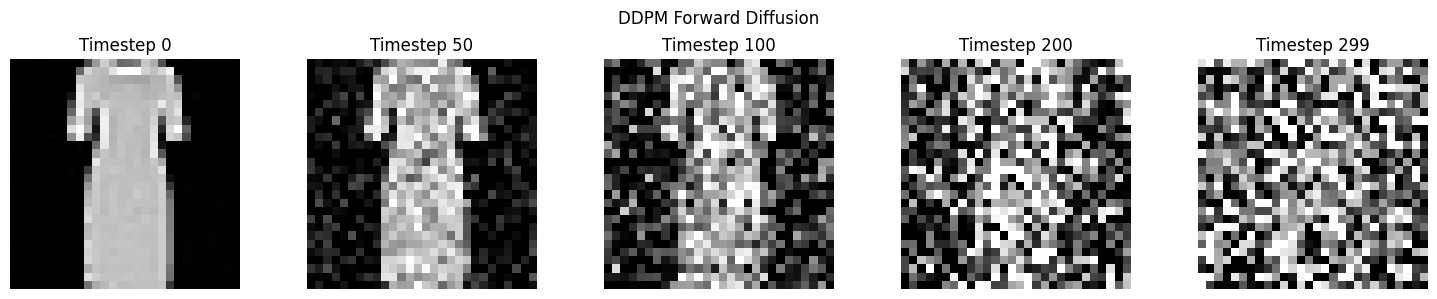

In [6]:
# Get one test image
image, label = test_dataset[0]

image = image.unsqueeze(0).to(device)

# Selected timesteps
selected_timesteps = [0, 50, 100, 200, 299]

plt.figure(figsize=(15, 3))

for i, t in enumerate(selected_timesteps):

    timestep = torch.tensor(
        [t],
        device=device
    )

    noisy_image, _ = forward_diffusion(
        image,
        timestep
    )

    noisy_image = noisy_image.squeeze().cpu()

    plt.subplot(1, 5, i + 1)
    plt.imshow(noisy_image, cmap="gray", vmin=-1, vmax=1)
    plt.title(f"Timestep {t}")
    plt.axis("off")

plt.suptitle("DDPM Forward Diffusion")
plt.tight_layout()
plt.show()

In [7]:
sample_images, _ = next(iter(train_loader))

sample_images = sample_images[:4].to(device)

test_t = torch.tensor(
    [0, 50, 150, 299],
    device=device
)

noisy_images, noise = forward_diffusion(
    sample_images,
    test_t
)

print("Original Shape:", sample_images.shape)
print("Noisy Shape:", noisy_images.shape)
print("Noise Shape:", noise.shape)
print("Device:", noisy_images.device)

Original Shape: torch.Size([4, 1, 28, 28])
Noisy Shape: torch.Size([4, 1, 28, 28])
Noise Shape: torch.Size([4, 1, 28, 28])
Device: cuda:0


In [8]:
def sinusoidal_embedding(t, dim):
    half_dim = dim // 2

    embeddings = math.log(10000) / (half_dim - 1)

    embeddings = torch.exp(
        torch.arange(
            half_dim,
            device=t.device
        ) * -embeddings
    )

    embeddings = t[:, None] * embeddings[None, :]

    embeddings = torch.cat(
        [torch.sin(embeddings), torch.cos(embeddings)],
        dim=-1
    )

    return embeddings

In [ ]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from models.ddpm import DDPMNetwork

In [10]:
model = DDPMNetwork(time_dim=128).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(model)

DDPMNetwork(
  (time_mlp): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
  )
  (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (bottleneck): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (up): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (output): Conv2d(128, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_projection): Linear(in_features=128, out_features=128, bias=True)
)


In [11]:
# Ambil 4 gambar
sample_images, _ = next(iter(train_loader))
sample_images = sample_images[:4].to(device)

# Tambahkan noise
test_t = torch.randint(
    0,
    TIMESTEPS,
    (4,),
    device=device
)

noisy_images, noise = forward_diffusion(
    sample_images,
    test_t
)

# Prediksi noise
model.eval()

with torch.no_grad():
    predicted_noise = model(noisy_images, test_t)

print("Input Shape:", noisy_images.shape)
print("Actual Noise Shape:", noise.shape)
print("Predicted Noise Shape:", predicted_noise.shape)
print("Device:", predicted_noise.device)

Input Shape: torch.Size([4, 1, 28, 28])
Actual Noise Shape: torch.Size([4, 1, 28, 28])
Predicted Noise Shape: torch.Size([4, 1, 28, 28])
Device: cuda:0


In [ ]:
def train_ddpm(model, train_loader, val_loader, epochs):

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Training
        model.train()

        running_loss = 0.0

        for images, _ in train_loader:

            images = images.to(device)
            batch_size = images.size(0)

            # Random timestep
            t = torch.randint(
                0,
                TIMESTEPS,
                (batch_size,),
                device=device
            )

            # Forward diffusion
            noisy_images, noise = forward_diffusion(
                images, t
            )

            # Predict noise
            predicted_noise = model(noisy_images, t)

            # Calculate loss
            loss = F.mse_loss(
                predicted_noise,
                noise
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = running_loss / len(train_loader)

        train_losses.append(avg_train_loss)

        # Validation
        model.eval()

        val_running_loss = 0.0

        with torch.no_grad():

            for images, _ in val_loader:

                images = images.to(device)
                batch_size = images.size(0)

                t = torch.randint(
                    0,
                    TIMESTEPS,
                    (batch_size,),
                    device=device
                )

                noisy_images, noise = forward_diffusion(
                    images, t
                )

                predicted_noise = model(noisy_images, t)

                val_loss = F.mse_loss(
                    predicted_noise,
                    noise
                )

                val_running_loss += val_loss.item()

        avg_val_loss = val_running_loss / len(val_loader)

        val_losses.append(avg_val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Val Loss: {avg_val_loss:.6f}"
        )

    return train_losses, val_losses

In [13]:
train_losses, val_losses = train_ddpm(
    model,
    train_loader,
    val_loader,
    EPOCHS
)

Epoch [1/30] Train Loss: 0.227675 Val Loss: 0.144205
Epoch [2/30] Train Loss: 0.133145 Val Loss: 0.128642
Epoch [3/30] Train Loss: 0.119892 Val Loss: 0.115237
Epoch [4/30] Train Loss: 0.113029 Val Loss: 0.112668
Epoch [5/30] Train Loss: 0.108764 Val Loss: 0.107585
Epoch [6/30] Train Loss: 0.106975 Val Loss: 0.105291
Epoch [7/30] Train Loss: 0.104200 Val Loss: 0.104547
Epoch [8/30] Train Loss: 0.102934 Val Loss: 0.100984
Epoch [9/30] Train Loss: 0.100368 Val Loss: 0.099691
Epoch [10/30] Train Loss: 0.100399 Val Loss: 0.097558
Epoch [11/30] Train Loss: 0.097698 Val Loss: 0.097194
Epoch [12/30] Train Loss: 0.096479 Val Loss: 0.098600
Epoch [13/30] Train Loss: 0.096439 Val Loss: 0.095155
Epoch [14/30] Train Loss: 0.096029 Val Loss: 0.093494
Epoch [15/30] Train Loss: 0.093821 Val Loss: 0.092334
Epoch [16/30] Train Loss: 0.093763 Val Loss: 0.093214
Epoch [17/30] Train Loss: 0.093137 Val Loss: 0.093346
Epoch [18/30] Train Loss: 0.093423 Val Loss: 0.091677
Epoch [19/30] Train Loss: 0.091530 Va

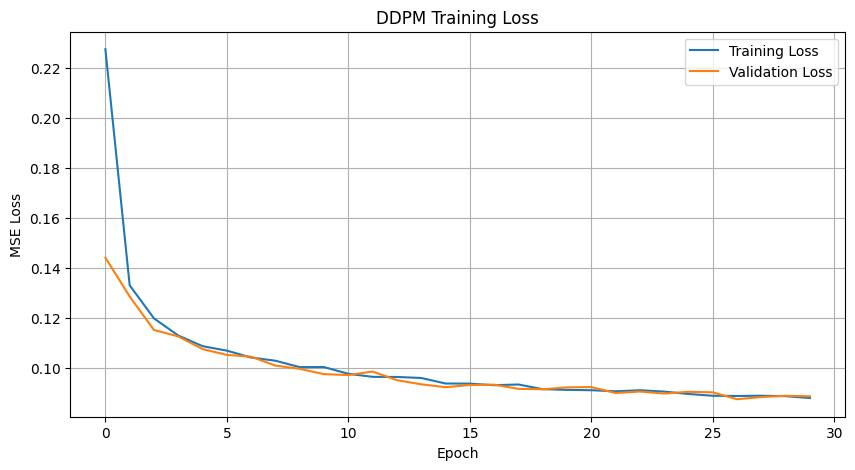

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")

plt.legend()
plt.grid(True)
plt.show()

In [15]:
import os

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)

torch.save(
    model.state_dict(),
    "../results/checkpoints/ddpm.pth"
)

print("DDPM checkpoint saved!")

DDPM checkpoint saved!


In [16]:
@torch.no_grad()
def reverse_diffusion(model, num_samples=16):

    model.eval()

    x = torch.randn(
        num_samples,
        CHANNELS,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=device
    )

    trajectory = []

    # Save initial noise
    trajectory.append(x[0].cpu().clone())

    for t in reversed(range(TIMESTEPS)):

        t_batch = torch.full(
            (num_samples,),
            t,
            device=device,
            dtype=torch.long
        )

        predicted_noise = model(x, t_batch)

        alpha = alphas[t]
        alpha_bar = alpha_bars[t]
        beta = betas[t]

        noise = (
            torch.randn_like(x)
            if t > 0
            else torch.zeros_like(x)
        )

        x = (1 / torch.sqrt(alpha)) * (
            x - (beta / torch.sqrt(1 - alpha_bar))
            * predicted_noise
        ) + torch.sqrt(beta) * noise

        # Save selected intermediate steps
        if t in [200, 100, 50, 10, 0]:
            trajectory.append(x[0].cpu().clone())

    return x, trajectory

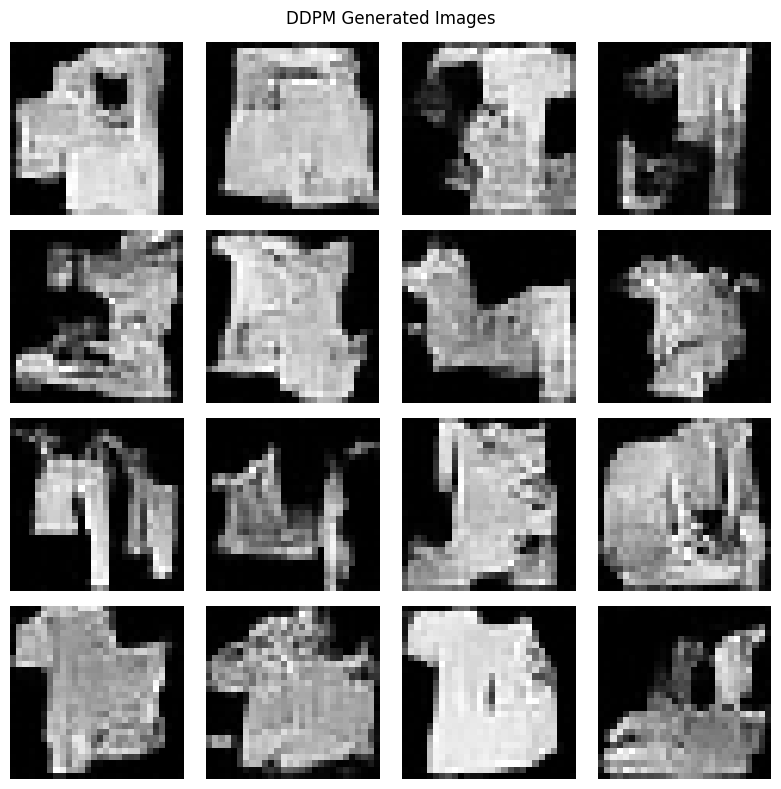

In [17]:
generated_images, trajectory = reverse_diffusion(
    model,
    num_samples=16
)

# Convert [-1, 1] to [0, 1]
generated_images = (
    generated_images.clamp(-1, 1) + 1
) / 2

generated_images = generated_images.cpu()

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("DDPM Generated Images")
plt.tight_layout()
plt.show()

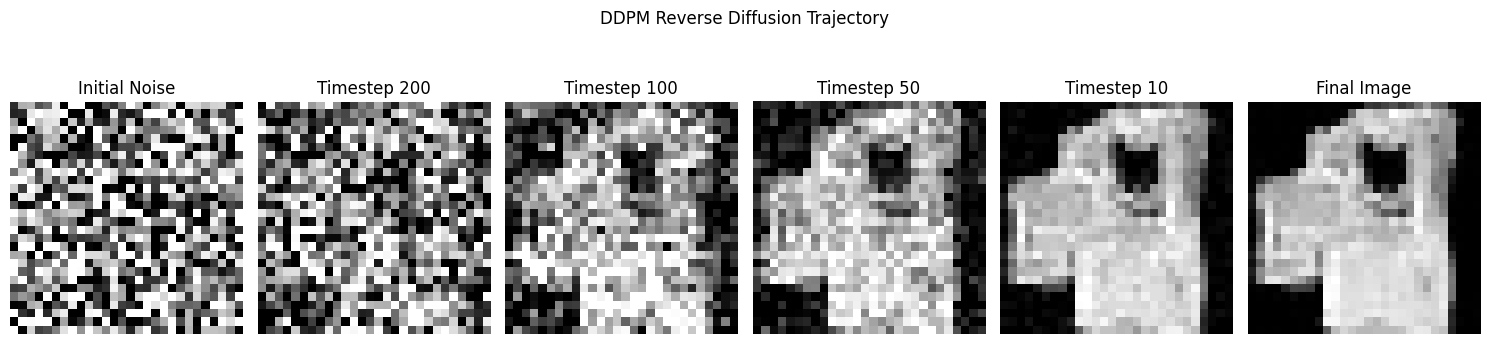

In [18]:
plt.figure(figsize=(15, 4))

trajectory_labels = [
    "Initial Noise",
    "Timestep 200",
    "Timestep 100",
    "Timestep 50",
    "Timestep 10",
    "Final Image"
]

for i, image in enumerate(trajectory):

    image = (image.clamp(-1, 1) + 1) / 2

    plt.subplot(1, len(trajectory), i + 1)

    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(trajectory_labels[i])
    plt.axis("off")

plt.suptitle("DDPM Reverse Diffusion Trajectory")
plt.tight_layout()
plt.show()

In [19]:
import os
from torchvision.utils import save_image

os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/generated_images", exist_ok=True)
os.makedirs("../results/plots", exist_ok=True)

# Save model
torch.save(
    model.state_dict(),
    "../results/checkpoints/ddpm.pth"
)

# Save generated images
save_image(
    generated_images,
    "../results/generated_images/ddpm_generated.png",
    nrow=4
)

# Save trajectory
trajectory_images = torch.stack(trajectory)

trajectory_images = (
    trajectory_images.clamp(-1, 1) + 1
) / 2

save_image(
    trajectory_images,
    "../results/generated_images/ddpm_trajectory.png",
    nrow=6
)

# Save training loss plot
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("DDPM Training Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "../results/plots/ddpm_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("DDPM results saved successfully!")

DDPM results saved successfully!
